Name - Devanshu Dave

---

Class - 4AI3 : Artificial Intelligence


---

File - Assignment 5


---
Student ID - 400502060



Number of filters =10+60(last two digit of my student id) = 70


In [20]:
import numpy as np

filter_size = 5
number_of_filters = 70
padding = 1
stride =2
max_pooling_size = 2
after_pool_stride = 1
hidden_neurons = 32
image_input_height = 28
imgae_input_width = 28
image_input_channels = 1
output_neurons = 10
flatten_parameters = 0
pooling_parmaters = 0

Calculate  convolutional layer output size

In [21]:
conv_output_width = ((image_input_height + np.multiply(2,padding) - filter_size) // stride) +1
conv_output_height = conv_output_width

calculating max pooling

In [22]:
pool_output_width = ((conv_output_height - max_pooling_size ) // after_pool_stride) +1
pool_output_height = pool_output_width
pool_output_width

np.int64(12)

flatten the pooling output

In [23]:
flatten_size = pool_output_height * pool_output_width * number_of_filters
flatten_size

np.int64(10080)

p_convolutional layer parmeter calculation

In [24]:
p_convolutional = (filter_size * filter_size * image_input_channels + 1) * number_of_filters
p_convolutional

1820

Calculating Dense Hidden Layer

In [25]:
p_dense = (flatten_size +1) * hidden_neurons
p_dense

np.int64(322592)

Output Layer

In [26]:
p_output_layer = (hidden_neurons + 1) * output_neurons
p_output_layer

330

Total Parameters

In [28]:

print("Convolutional layer parameters = ",p_convolutional + p_dense+p_output_layer + flatten_parameters + pooling_parmaters )

Convolutional layer parameters =  324742


Question 2

In [29]:
from keras.src.layers.reshaping.zero_padding2d import ZeroPadding2D
# Simple CNN for the MNIST Dataset
import numpy as np
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Dropout
from keras.layers import Flatten
from keras.layers import Conv2D
from keras.layers import MaxPooling2D
from keras import utils
# fix dimension ordering issue
from keras import backend as K

#K.set_image_dim_ordering('th')
K.set_image_data_format('channels_last')

# fix random seed for reproducibility
seed = 7
np.random.seed(seed)
# load data
(X_train, y_train), (X_test, y_test) = mnist.load_data()
# reshape to be [samples][channels][width][height]
X_train = X_train.reshape(X_train.shape[0], 28, 28, 1).astype('float32')
X_test = X_test.reshape(X_test.shape[0], 28, 28, 1).astype('float32')
# normalize inputs from 0-255 to 0-1
X_train = X_train / 255
X_test = X_test / 255
# one hot encode outputs
yc_train = utils.to_categorical(y_train)
yc_test = utils.to_categorical(y_test)
num_classes = yc_test.shape[1]
# define a simple CNN model
def baseline_model():
    # create model
    model = Sequential()
    model.add(ZeroPadding2D(padding=1,input_shape=(28,28,1)))
    model.add(Conv2D(70, (5, 5),strides= (2,2), input_shape=(28, 28, 1), activation='relu', padding='valid'))
    model.add(MaxPooling2D(pool_size=(2, 2),strides = (1,1)))

    model.add(Flatten())
    model.add(Dense(32, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))
    # Compile model
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model
# build the model
model = baseline_model()
# Initial model evaluation
scores = model.evaluate(X_test, yc_test, verbose=0)
print("CNN error before training: %.2f%%" % (100-scores[1]*100))

CNN error before training: 89.40%


In [30]:
# Fit the model
model.fit(X_train, yc_train, validation_data=(X_test, yc_test), epochs=10, batch_size=200)
# Final evaluation of the model
scores = model.evaluate(X_test, yc_test, verbose=0)
print("CNN Error: %.2f%%" % (100-scores[1]*100))

Epoch 1/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 30s 96ms/step - accuracy: 0.9265 - loss: 0.2468 - val_accuracy: 0.9797 - val_loss: 0.0683
Epoch 2/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 28s 95ms/step - accuracy: 0.9803 - loss: 0.0678 - val_accuracy: 0.9821 - val_loss: 0.0498
Epoch 3/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 29s 95ms/step - accuracy: 0.9849 - loss: 0.0502 - val_accuracy: 0.9853 - val_loss: 0.0431
Epoch 4/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 41s 94ms/step - accuracy: 0.9887 - loss: 0.0384 - val_accuracy: 0.9868 - val_loss: 0.0408
Epoch 5/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 41s 95ms/step - accuracy: 0.9900 - loss: 0.0332 - val_accuracy: 0.9883 - val_loss: 0.0346
Epoch 6/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 41s 96ms/step - accuracy: 0.9915 - loss: 0.0275 - val_accuracy: 0.9888 - val_loss: 0.0349
Epoch 7/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 29s 96ms/step - accuracy: 0.9925 - loss: 0.0236 - val_accuracy: 0.9898 - val_loss: 0.0331
Epoch 8/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 29s 95ms/step - accuracy: 0.9943 - loss: 0.0189 - 

In [31]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ zero_padding2d_1                │ (None, 30, 30, 1)      │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 70)     │         1,820 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 70)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 10080)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │       322,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 974,228 (3.72 MB)

 Trainable params: 324,742 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 649,486 (2.48 MB)

9
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
[1.1657385e-09 1.2082128e-13 2.8279104e-08 7.2994709e-07 1.3963897e-07
 4.0121386e-09 1.8102151e-15 1.8609559e-05 6.2490813e-06 9.9997419e-01]


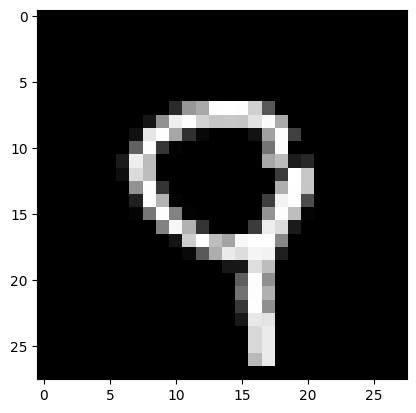

In [32]:
import matplotlib.pyplot as plt
NNpredict = model.predict(X_test, verbose=0)
y_Hat=np.argmax(NNpredict, axis=1)
n=235
print(y_Hat[n])
print(yc_test[n])
print(NNpredict[n])
plt.imshow(X_test[n], cmap='gray')
plt.show()